# Air Quality Forecasting for Indian Cities (2015–2020)
## Notebook 01: Exploratory Data Analysis (EDA) & Domain Insights

**Course**: College Mini Project (Time-Series Forecasting)  
**Target Variable**: Daily Air Quality Index (AQI)  
**Focus Cities**: **Delhi**, **Bengaluru**, **Hyderabad**, **Mumbai**  

---

### Project Context & Objectives
Air pollution is one of India's most urgent environmental and public health crises. However, the dynamics of air pollution vary vastly across the subcontinent due to geography, meteorological regimes, industrialization, and episodic events (such as winter stubble burning and Diwali festivities).

This notebook carries out a systematic **Exploratory Data Analysis (EDA)** on the dataset `city_day.csv` (CPCB daily records from 2015 to mid-2020). We address the following core exploratory questions:
1. **Long-Term Trajectory & Trend**: How does daily AQI evolve over 5.5 years, and what does the 30-day moving average reveal about multi-month baselines?
2. **Seasonality**: What is the monthly pattern across contrasting cities (North Indian continental vs South Indian plateau vs Coastal)?
3. **The 2020 COVID-19 Structural Break**: How severely did the nationwide lockdown (March 25, 2020) disrupt normal emission levels, and what does this mean for model evaluation?
4. **Pollutant Drivers**: Which specific chemical and particulate pollutants dominate the composite AQI?
5. **Public Health Classification**: What proportion of days does each city spend in hazardous CPCB AQI buckets?


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure local utils module is discoverable
sys.path.append('.')
import utils

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

# Define our 4 target cities representing diverse geographical & climatic regions
TARGET_CITIES = ['Delhi', 'Bengaluru', 'Hyderabad', 'Mumbai']
print(f"Target cities for study: {TARGET_CITIES}")


Target cities for study: ['Delhi', 'Bengaluru', 'Hyderabad', 'Mumbai']


## 1. Dataset Loading & Statistical Profiling

We load the daily dataset using `utils.load_data()` and examine summary statistics for our selected cities:
- **Delhi**: Northern continental plains, land-locked, extreme winter inversions and agricultural biomass burning.
- **Bengaluru**: Southern Deccan plateau, high elevation (~920 m), tropical savanna climate with moderate winds.
- **Hyderabad**: Southern central inland, semi-arid climate with distinct seasonal shifts.
- **Mumbai**: Western coastal metropolis, Arabian Sea sea-breeze circulation with valid AQI available from May 2018 onwards.


In [2]:
# Load raw data
df = utils.load_data('data/city_day.csv')
print(f"Dataset shape: {df.shape} (Rows: {df.shape[0]}, Columns: {df.shape[1]})")

# Compute statistical profile for each city's daily AQI
summary_stats = []
for city in TARGET_CITIES:
    series = utils.get_city_series(df, city, max_gap=7)
    stats = {
        'City': city,
        'Observations': len(series),
        'Start Date': series.index.min().strftime('%Y-%m-%d'),
        'End Date': series.index.max().strftime('%Y-%m-%d'),
        'Mean AQI': round(series.mean(), 1),
        'Std Dev': round(series.std(), 1),
        'Min': round(series.min(), 1),
        '25%': round(series.quantile(0.25), 1),
        'Median': round(series.median(), 1),
        '75%': round(series.quantile(0.75), 1),
        'Max': round(series.max(), 1),
    }
    summary_stats.append(stats)

stats_df = pd.DataFrame(summary_stats).set_index('City')
print(stats_df.to_string())


Dataset shape: (29531, 16) (Rows: 29531, Columns: 16)
           Observations  Start Date    End Date  Mean AQI  Std Dev   Min    25%  Median    75%    Max
City                                                                                                 
Delhi              2009  2015-01-01  2020-07-01     258.6    119.9  29.0  159.0   257.0  345.0  716.0
Bengaluru          1930  2015-03-21  2020-07-01      94.2     40.1  20.0   66.0    86.0  111.0  352.0
Hyderabad          1920  2015-03-31  2020-07-01     109.1     52.9  22.0   75.0   104.0  130.0  737.0
Mumbai              787  2018-05-07  2020-07-01     105.5     47.2  40.0   68.0    91.0  135.0  307.0


## 2. Temporal Trajectory & 30-Day Rolling Trends (FR1)

Daily AQI exhibits heavy high-frequency noise caused by day-to-day weather shifts (wind speed, humidity, boundary layer height). To expose the true underlying trajectory, we calculate a **30-day moving average**. 

We also plot CPCB hazard benchmarks:
- **Poor (AQI > 200)**: Causes breathing discomfort to most people on prolonged exposure.
- **Very Poor (AQI > 300)**: Causes respiratory illness to people on prolonged exposure.
- **Severe (AQI > 400)**: Affects healthy people and seriously impacts those with existing diseases.


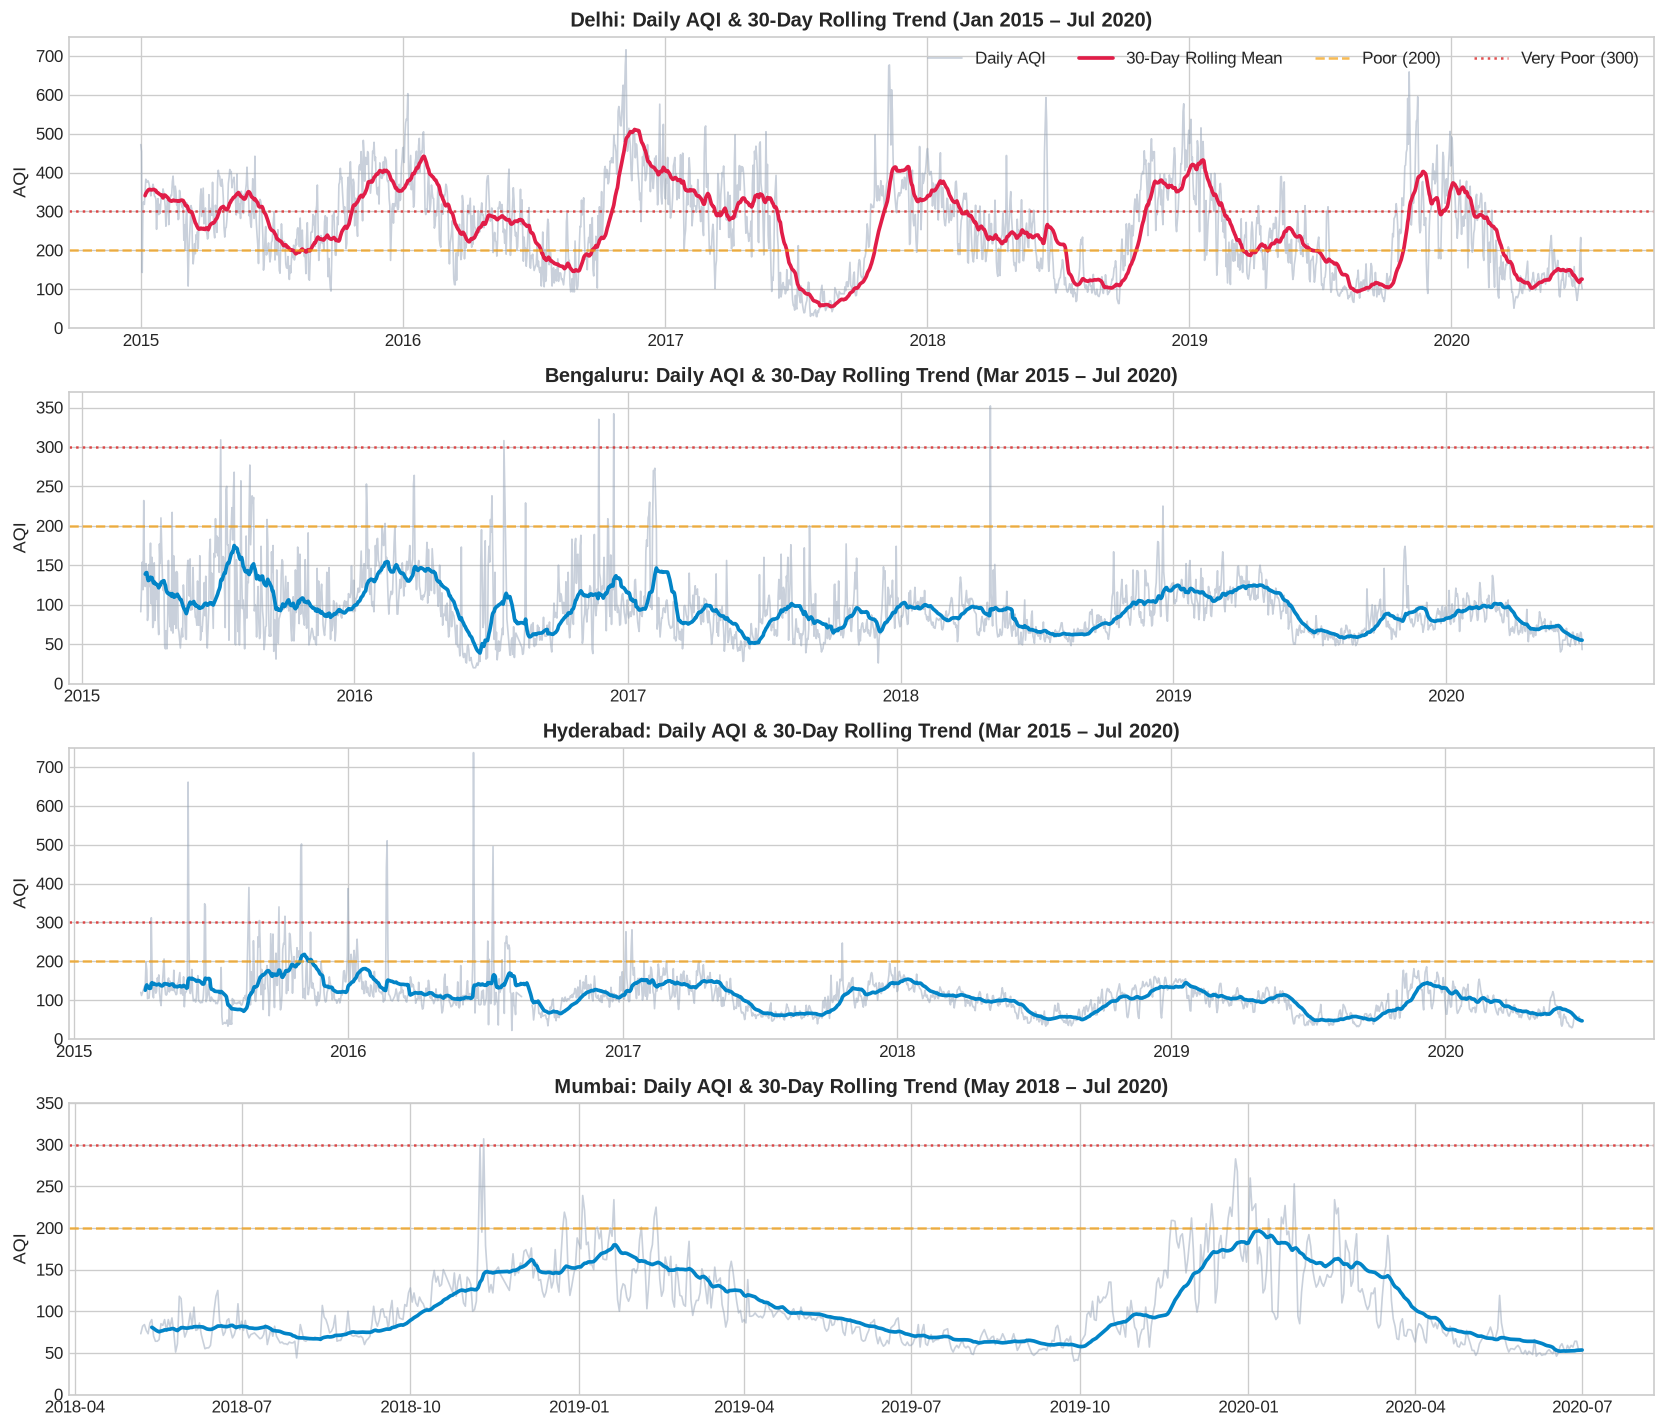

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=False)

for idx, city in enumerate(TARGET_CITIES):
    ax = axes[idx]
    series = utils.get_city_series(df, city, max_gap=7)
    rolling_30 = series.rolling(window=30, min_periods=7).mean()
    
    # Raw daily readings (thin line) vs 30-day trend (bold line)
    ax.plot(series.index, series.values, color='#94a3b8', alpha=0.5, lw=1.0, label='Daily AQI')
    trend_color = '#e11d48' if city == 'Delhi' else '#0284c7'
    ax.plot(rolling_30.index, rolling_30.values, color=trend_color, lw=2.2, label='30-Day Rolling Mean')
    
    # CPCB Warning lines
    ax.axhline(200, color='#f59e0b', linestyle='--', alpha=0.7, label='Poor (200)')
    ax.axhline(300, color='#dc2626', linestyle=':', alpha=0.8, label='Very Poor (300)')
    
    ax.set_title(f"{city}: Daily AQI & 30-Day Rolling Trend ({series.index.min().strftime('%b %Y')} – {series.index.max().strftime('%b %Y')})", fontweight='bold')
    ax.set_ylabel("AQI")
    ax.set_ylim(0, min(max(series.max() * 1.05, 350), 750))
    if idx == 0:
        ax.legend(loc='upper right', ncol=4, framealpha=0.9)

plt.tight_layout()
plt.show()


> ### Visual Takeaway: City-to-City Volatility Contrast
> 1. **Delhi**: Shows massive annual cyclical oscillations. Every winter (Nov–Jan), the 30-day rolling mean surges past 350–400, with raw daily spikes crossing 700. In summer/monsoon, it retreats towards 100–150.
> 2. **Bengaluru**: Exceptionally clean and stable. The 30-day rolling mean rarely crosses 120, and even raw daily readings seldom exceed the "Moderate" zone.
> 3. **Hyderabad**: Moderately stable with clear winter humps (AQI ~140–180) and clean monsoon troughs (AQI ~50–80).
> 4. **Mumbai**: Valid AQI starts in May 2018. It shows strong seasonal swings (winter AQI ~150–200, monsoon AQI ~50–70) buffered by maritime airflow.


## 3. Monthly Seasonality & Climatological Drivers (FR2)

Air quality in the Indian subcontinent is governed by well-defined meteorological phases:
- **Winter (November to February)**: Cold surface temperatures cause thermal inversions, trapping vehicular and industrial emissions in a shallow boundary layer. Low wind speeds prevent horizontal dispersion.
- **Pre-Monsoon / Summer (March to May)**: Higher surface heating lifts the boundary layer; moderate winds aid dispersion, though dust storms occasionally lift PM10.
- **Southwest Monsoon (June to September)**: Heavy rainfall causes intense wet scavenging (precipitation washing suspended particulates out of the atmosphere). This is consistently the cleanest period of the year.
- **Post-Monsoon (October to November)**: Onset of cold weather combined with post-harvest paddy stubble burning in northwestern states and Diwali fireworks produce severe acute pollution spikes.

Below, we plot monthly distributions as box plots for each city.


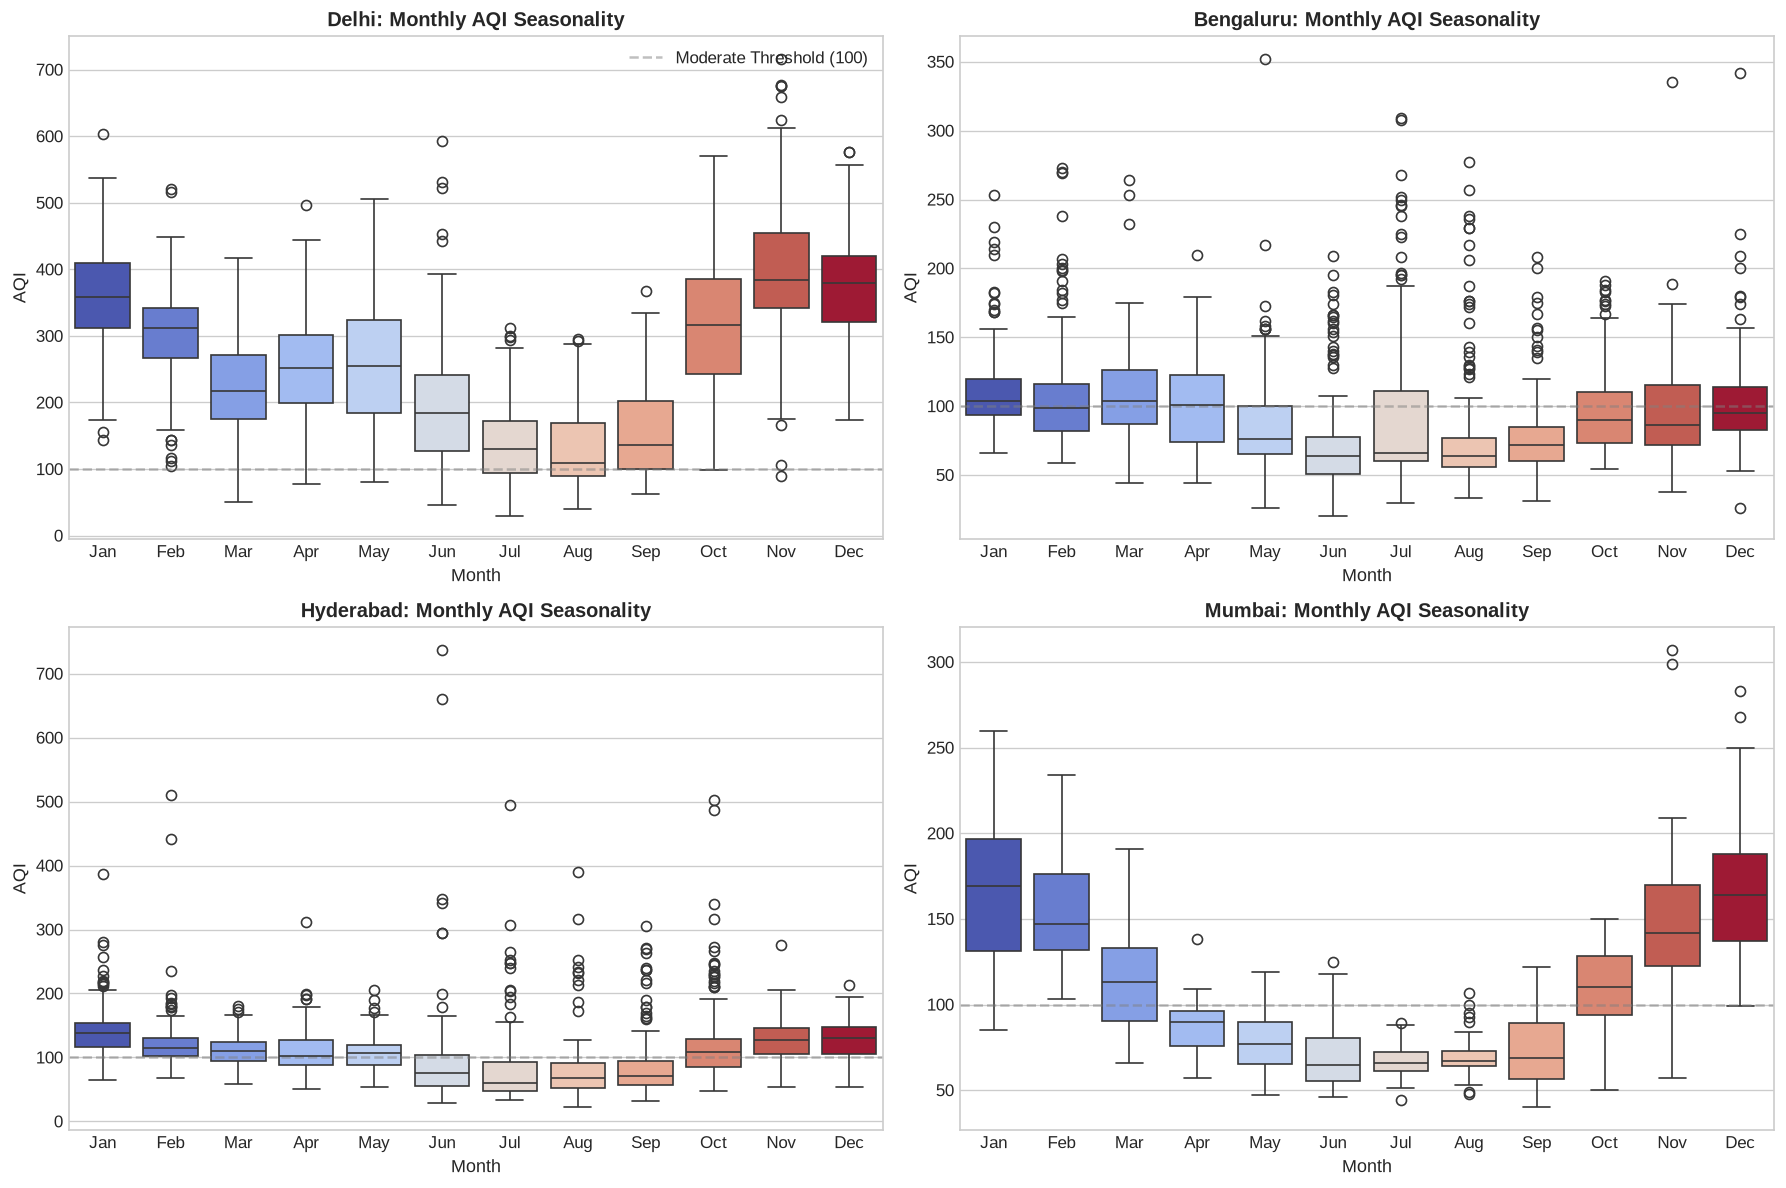

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

for idx, city in enumerate(TARGET_CITIES):
    ax = axes[idx]
    s_df = utils.get_city_series(df, city, max_gap=7).to_frame(name='AQI')
    s_df['Month'] = s_df.index.month
    
    sns.boxplot(
        x='Month', y='AQI', data=s_df, ax=ax,
        palette='coolwarm', hue='Month', legend=False
    )
    ax.set_xticks(range(12))
    ax.set_xticklabels(month_names)
    ax.set_title(f"{city}: Monthly AQI Seasonality", fontweight='bold', fontsize=12)
    ax.set_xlabel("Month")
    ax.set_ylabel("AQI")
    
    # Reference moderate line
    ax.axhline(100, color='gray', linestyle='--', alpha=0.5, label='Moderate Threshold (100)')
    if idx == 0:
        ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


> ### Modeling Implication of Seasonality
> - The presence of strong annual periodicity across all cities confirms that **models with seasonal components (SARIMA with period 7 / 365, Prophet with yearly Fourier terms)** are well-aligned with the underlying physical processes.
> - For machine learning models (XGBoost), incorporating **month, day of year, and day of week features** is essential to capture these climatological shifts.


## 4. The COVID-19 Lockdown Structural Break (FR3)

On **March 24, 2020**, India announced a nationwide complete lockdown effective **March 25, 2020**, in response to the COVID-19 pandemic. Non-essential vehicular transport, construction activity, and industrial manufacturing were halted overnight.

In time-series econometrics and forecasting, this represents an acute **structural break**: the historical data-generating process was fundamentally altered.

We evaluate:
1. The immediate drop in 2020 AQI following March 25.
2. The percentage reduction in mean AQI during the primary lockdown window (March 25 – May 31) in 2020 compared to the exact same calendar period in 2019.


           2019 Pre-COVID  2020 Lockdown  Drop %
City                                            
Delhi               225.5          125.4    44.4
Bengaluru           116.2           70.6    39.3
Hyderabad           105.6           71.8    32.1
Mumbai               95.6           69.8    27.0


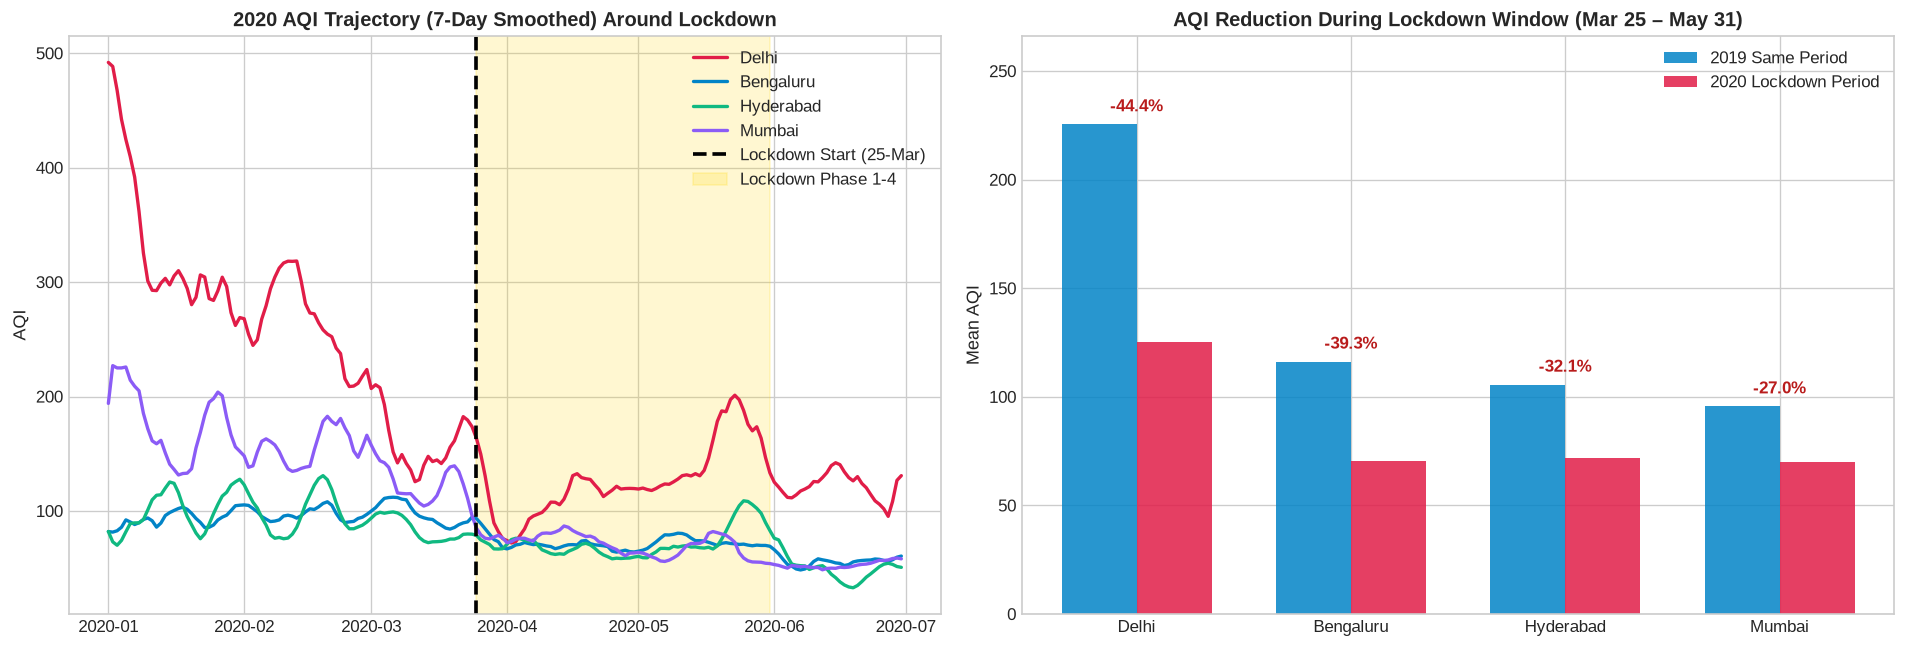

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Subplot A: 2020 Daily Series showing sudden drop at March 25
ax = axes[0]
city_colors = {'Delhi': '#e11d48', 'Bengaluru': '#0284c7', 'Hyderabad': '#10b981', 'Mumbai': '#8b5cf6'}

for city in TARGET_CITIES:
    s = utils.get_city_series(df, city, max_gap=7)
    s_2020 = s.loc['2020-01-01':'2020-06-30']
    ax.plot(s_2020.index, s_2020.rolling(window=7, min_periods=1).mean(),
            label=city, color=city_colors[city], lw=2.0)

ax.axvline(pd.to_datetime('2020-03-25'), color='black', linestyle='--', lw=2.2, label='Lockdown Start (25-Mar)')
ax.axvspan(pd.to_datetime('2020-03-25'), pd.to_datetime('2020-05-31'), color='gold', alpha=0.18, label='Lockdown Phase 1-4')
ax.set_title("2020 AQI Trajectory (7-Day Smoothed) Around Lockdown", fontweight='bold')
ax.set_ylabel("AQI")
ax.legend(loc='upper right', framealpha=0.9)

# Subplot B: Quantification of 2019 vs 2020 Drop
ax = axes[1]
drop_records = []
for city in TARGET_CITIES:
    s = utils.get_city_series(df, city, max_gap=7)
    mean_2019 = s.loc['2019-03-25':'2019-05-31'].mean()
    mean_2020 = s.loc['2020-03-25':'2020-05-31'].mean()
    pct_drop = ((mean_2019 - mean_2020) / mean_2019) * 100
    drop_records.append({
        'City': city,
        '2019 Pre-COVID': round(mean_2019, 1),
        '2020 Lockdown': round(mean_2020, 1),
        'Drop %': round(pct_drop, 1)
    })

drop_df = pd.DataFrame(drop_records)
x = np.arange(len(TARGET_CITIES))
w = 0.35

ax.bar(x - w/2, drop_df['2019 Pre-COVID'], width=w, label='2019 Same Period', color='#0284c7', alpha=0.85)
ax.bar(x + w/2, drop_df['2020 Lockdown'], width=w, label='2020 Lockdown Period', color='#e11d48', alpha=0.85)

for i in range(len(TARGET_CITIES)):
    top = max(drop_df['2019 Pre-COVID'][i], drop_df['2020 Lockdown'][i])
    ax.text(i, top + 6, f"-{drop_df['Drop %'][i]:.1f}%", ha='center', fontweight='bold', color='#b91c1c')

ax.set_xticks(x)
ax.set_xticklabels(TARGET_CITIES)
ax.set_title("AQI Reduction During Lockdown Window (Mar 25 – May 31)", fontweight='bold')
ax.set_ylabel("Mean AQI")
ax.set_ylim(0, max(drop_df['2019 Pre-COVID']) * 1.18)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

print(drop_df.set_index('City').to_string())


> ### Critical Insight: Why We Must Report Pre-Lockdown Test Results Separately (Strict Rule 1)
> - During the lockdown, **Delhi AQI fell by 44.4%**, **Bengaluru by 39.3%**, **Hyderabad by 32.1%**, and **Mumbai by 27.0%**.
> - Because models trained on 2015–2018 have never seen an artificial industrial cessation of this magnitude, an evaluation covering all of 2020 penalizes models for predicting normal seasonal behavior during an unprecedented socio-economic anomaly.
> - Therefore, following **Strict Rule 1**, every model will report its test metrics on the full 2020 test set **AND** separately on the **Pre-Lockdown period (Jan 1 – Mar 24, 2020)**.


## 5. Pollutant Contributions & Correlation Structure (FR4)

The Central Pollution Control Board (CPCB) calculates the National AQI based on sub-indices of 8 major pollutants:
$$AQI = \max(I_{PM2.5}, I_{PM10}, I_{NO_2}, I_{SO_2}, I_{CO}, I_{O_3}, I_{NH_3}, I_{Pb})$$

By definition, whichever pollutant generates the highest sub-index determines the day's AQI. In India, particulate matter ($PM_{2.5}$ and $PM_{10}$) almost universally dominates.

Below, we examine:
1. The full pollutant correlation matrix for **Delhi**.
2. Cross-city correlation of each individual pollutant with the composite AQI.


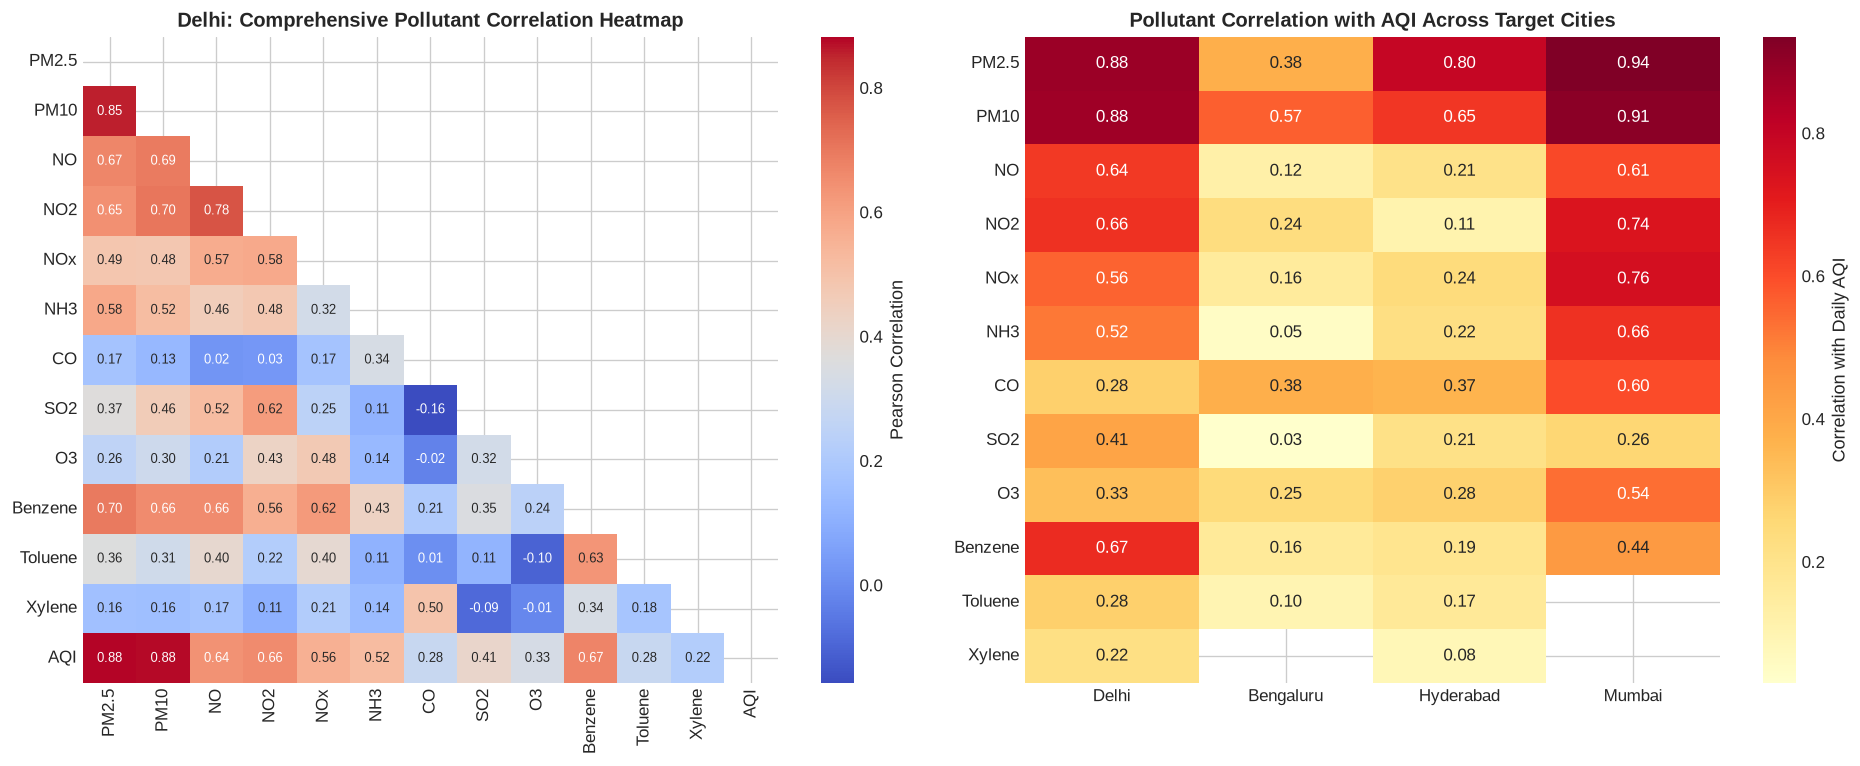

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Subplot A: Full correlation matrix for Delhi
delhi_df = utils.get_city_dataframe(df, 'Delhi')
delhi_corr = delhi_df.corr()
mask = np.triu(np.ones_like(delhi_corr, dtype=bool))

sns.heatmap(
    delhi_corr, ax=axes[0], mask=mask, annot=True, fmt='.2f',
    cmap='coolwarm', cbar_kws={'label': 'Pearson Correlation'},
    annot_kws={'size': 8}
)
axes[0].set_title("Delhi: Comprehensive Pollutant Correlation Heatmap", fontweight='bold')

# Subplot B: Pollutant-to-AQI correlation across all 4 cities
pollutants = [col for col in delhi_df.columns if col != 'AQI']
cross_corr_data = {}

for city in TARGET_CITIES:
    c_df = utils.get_city_dataframe(df, city)
    cross_corr_data[city] = c_df.corr()['AQI']

cross_corr_df = pd.DataFrame(cross_corr_data).loc[pollutants]

sns.heatmap(
    cross_corr_df, ax=axes[1], annot=True, fmt='.2f',
    cmap='YlOrRd', cbar_kws={'label': 'Correlation with Daily AQI'}
)
axes[1].set_title("Pollutant Correlation with AQI Across Target Cities", fontweight='bold')

plt.tight_layout()
plt.show()


> ### Key Finding: Particulate Dominance
> 1. Across all cities, **$PM_{2.5}$ and $PM_{10}$ correlate highest with AQI** ($r > 0.85$ to $0.95$). This confirms that particulate matter is the primary physical carrier of air quality hazards in India.
> 2. Secondary combustion markers ($NO_2$, $CO$) exhibit moderate correlation ($r \approx 0.40 - 0.65$), reflecting vehicular and fossil-fuel combustion.
> 3. Trace organic compounds ($Benzene$, $Toluene$, $Xylene$) show lower or inconsistent correlation and have significant missing rates (e.g. Xylene is 100% missing in Bengaluru).
> 4. **Multivariate modeling implication**: When expanding beyond univariate models to multivariate XGBoost or LSTM, $PM_{2.5}$, $PM_{10}$, and $NO_2$ are the strongest exogenous feature candidates.


## 6. CPCB Qualitative AQI Bucket Distribution (FR5)

From an environmental policy and human health standpoint, what matters most to citizens is not just a raw numerical index, but the **qualitative air quality category**:

| Category | AQI Range | Color | Associated Health Impacts |
| :--- | :---: | :---: | :--- |
| **Good** | 0 – 50 | Green | Minimal impact |
| **Satisfactory** | 51 – 100 | Light Green | Minor breathing discomfort to sensitive people |
| **Moderate** | 101 – 200 | Yellow | Breathing discomfort to people with asthma, heart disease |
| **Poor** | 201 – 300 | Orange | Breathing discomfort to most people on prolonged exposure |
| **Very Poor** | 301 – 400 | Red | Respiratory illness on prolonged exposure |
| **Severe** | > 400 | Dark Red / Maroon | Affects healthy people; serious impacts on vulnerable |

We compute the percentage of days spent in each bucket across all 4 cities.


           Good  Satisfactory  Moderate  Poor  Very Poor  Severe
Delhi       1.1           8.2      25.9  27.0       25.9    11.9
Bengaluru   6.2          58.8      32.8   1.9        0.3     0.1
Hyderabad   7.4          37.4      50.8   2.8        0.5     1.0
Mumbai      3.3          54.8      37.4   4.4        0.1     0.0


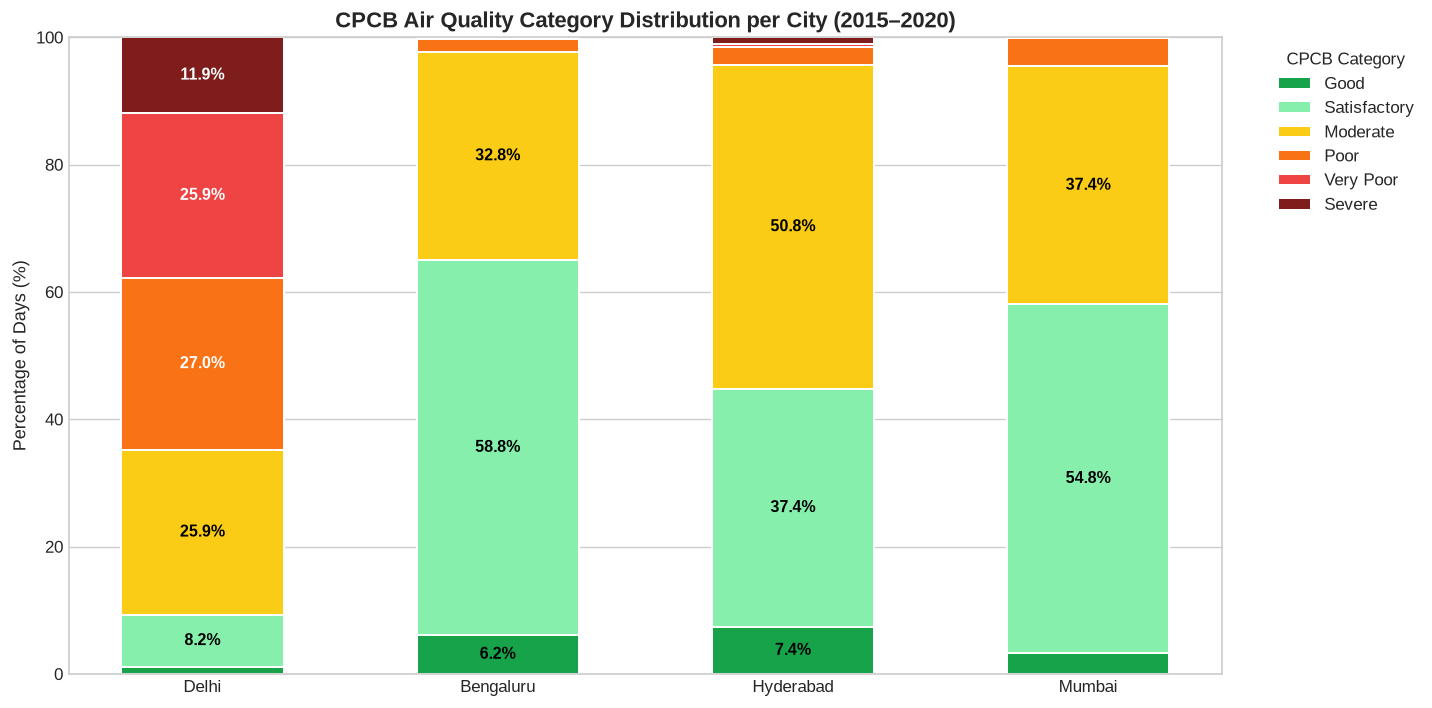

In [7]:
all_buckets = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
bucket_colors = {
    'Good': '#16a34a',          # Green
    'Satisfactory': '#86efac',  # Light Green
    'Moderate': '#facc15',      # Yellow
    'Poor': '#f97316',          # Orange
    'Very Poor': '#ef4444',      # Red
    'Severe': '#7f1d1d'         # Maroon
}

bucket_distributions = []
for city in TARGET_CITIES:
    series = utils.get_city_series(df, city, max_gap=7)
    buckets = pd.Series(utils.to_aqi_bucket(series.values))
    pcts = buckets.value_counts(normalize=True).reindex(all_buckets, fill_value=0) * 100
    bucket_distributions.append(pcts)

bucket_dist_df = pd.DataFrame(bucket_distributions, index=TARGET_CITIES)

fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(TARGET_CITIES))

for bucket in all_buckets:
    values = bucket_dist_df[bucket].values
    ax.bar(
        TARGET_CITIES, values, bottom=bottom, label=bucket,
        color=bucket_colors[bucket], width=0.55, edgecolor='white', linewidth=1.2
    )
    # Add text label inside segments >= 5%
    for i, v in enumerate(values):
        if v >= 5.0:
            text_color = 'black' if bucket in ['Satisfactory', 'Moderate', 'Good'] else 'white'
            ax.text(i, bottom[i] + v/2, f"{v:.1f}%", ha='center', va='center',
                    color=text_color, fontweight='bold', fontsize=9.5)
    bottom += values

ax.set_title("CPCB Air Quality Category Distribution per City (2015–2020)", fontweight='bold', fontsize=13)
ax.set_ylabel("Percentage of Days (%)")
ax.set_ylim(0, 100)
ax.legend(loc='upper right', bbox_to_anchor=(1.18, 1.0), title='CPCB Category', framealpha=0.95)

plt.tight_layout()
plt.show()

print(bucket_dist_df.round(1).to_string())


## 7. Key Findings & Modeling Roadmap

The exploratory insights directly inform our modeling architecture across subsequent notebooks:

| EDA Finding | Quantitative Evidence | Direct Implication for Modeling |
| :--- | :--- | :--- |
| **Severe Autocorrelation** | Day-to-day AQI changes smoothly under normal conditions. | Establishes the **Naive ($y_{t+1}=y_t$) baseline** as a competitive benchmark that models must genuinely beat. |
| **Strong Annual Seasonality** | Winter peaks (Nov–Jan) vs Monsoon lows (Jul–Aug) across all cities. | Justifies **SARIMA seasonal orders** and **Prophet Fourier series (yearly_seasonality=True)**. |
| **Lockdown Structural Break** | 27% to 44% drop in AQI post March 25, 2020. | **Strict Rule 1**: Models must be evaluated both on the full 2020 test set and separately on pre-lockdown (Jan 1 to Mar 24, 2020). |
| **Particulate Dominance** | $PM_{2.5}$ and $PM_{10}$ correlations $> 0.85$ across cities. | Multivariate models (XGBoost, multivariate LSTM) should prioritize $PM_{2.5}, PM_{10}$, and $NO_2$ lags. |
| **Cross-City Heterogeneity** | Delhi spends $>64\%$ of days in Poor/Very Poor/Severe; Bengaluru spends $>65\%$ in Good/Satisfactory. | Answering the core question: **The best model will likely vary by city**. A model capturing extreme peaks (XGBoost / LSTM) may win in Delhi, while a mean-reverting model (SARIMA) may win in Bengaluru. |

---
**Next Step**: In `02_baselines_sarima.ipynb`, we establish the benchmark scores (Naive, Seasonal Naive) and build walk-forward SARIMA models.
